<p align="center">
  <img src="./google.png" alt="Netflix Banner" width="100%">
</p>

### 📊 Project Metadata
* **Project Name:** Google Play Store Market Analysis
* **Dataset:** 10,841 Google Play Store Apps (`googleplaystore.csv`)
* **Tech Stack:** Python, Pandas, NumPy, Matplotlib, Seaborn
* **Focus Areas:** Data Cleaning, Feature Engineering, Distribution Analysis, Market Insights

---

## 📌 Project Overview

This notebook presents an end-to-end **Exploratory Data Analysis (EDA)** on the Google Play Store ecosystem to identify app category saturation, pricing strategies, user rating distributions, and download drivers.

### Key Analytical Goals:
1. **Data Hygiene & Auditing:** Clean complex string entries (sizes, prices, installs), fix structural array-shifts, and deduplicate multi-scrape app records.
2. **Feature Engineering:** Log-scale highly skewed engagement metrics (`Installs`, `Reviews`) and convert raw sizes into normalized Megabyte values (`size_mb`).
3. **Market Segmentation:** Analyze freemium vs. paid adoption, category density, and rating trends to uncover actionable insights for app publishers.

---

## 📑 Table of Contents
1. [Environment Setup & Data Ingestion](#1-environment-setup--data-ingestion)
2. [Data Health Audit & Integrity Checks](#2-data-health-audit--integrity-checks)
3. [Data Preprocessing & Feature Engineering](#3-data-preprocessing--feature-engineering)
4. [Univariate Exploratory Data Analysis](#4-univariate-exploratory-data-analysis)
5. [Bivariate & Category Deep-Dive](#5-bivariate--category-deep-dive)
6. [Executive Summary & Key Takeaways](#6-executive-summary--key-takeaways)

## Environment Setup & Data Ingestion

> **Objective:** Import essential analytical libraries, establish a cohesive visualization design system for a polished GitHub presentation, and ingest the raw Play Store dataset.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

df_raw = pd.read_csv(r"C:\DATA ANALYTICS\DA WITH PYTHON\googleplaystore.csv")
df = df_raw.copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [5]:
print("Columns:", df.columns.tolist())
df.info()

display(df.describe(include="all").T)

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing)

Columns: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Content Rating,1,0.01
Type,1,0.01
Size,0,0.00
Reviews,0,0.00
Category,0,0.00
App,0,0.00
Price,0,0.00


In [6]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated app-name rows:", df["App"].duplicated().sum())

print("\nType values:")
display(df["Type"].value_counts(dropna=False))

print("\nRatings outside 1–5:")
display(df.loc[df["Rating"].notna() & ~df["Rating"].between(1, 5),
               ["App", "Category", "Rating"]].head(20))

print("\nPotential malformed category records:")
display(df["Category"].value_counts(dropna=False).tail(10))

Exact duplicate rows: 483
Repeated app-name rows: 1181

Type values:


Type
Free    10039
Paid      800
NaN         1
0           1
Name: count, dtype: int64


Ratings outside 1–5:


,App,Category,Rating
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0



Potential malformed category records:


Category
HOUSE_AND_HOME        88
AUTO_AND_VEHICLES     85
LIBRARIES_AND_DEMO    85
WEATHER               82
ART_AND_DESIGN        65
EVENTS                64
COMICS                60
PARENTING             60
BEAUTY                53
1.9                    1
Name: count, dtype: int64

This file has 483 exact duplicate rows and 1,181 repeated app-name rows before cleaning. It also contains at least one invalid rating (19.0), which cannot be a valid Play Store rating. The next step removes exact duplicates and keeps one record per app using a documented rule; this is a pragmatic EDA choice, not proof that every repeated name is erroneous.

In [7]:
# Trim strings without changing missing values
for col in df.select_dtypes(include=["object","str"]).columns:
    df[col] = df[col].str.strip()

# Remove exact duplicates
df = df.drop_duplicates().copy()

# Correct known invalid Type placeholder
df["Type"] = df["Type"].replace("0", np.nan)

# Numeric conversions
df["reviews_num"] = pd.to_numeric(df["Reviews"], errors="coerce")

df["installs_num"] = pd.to_numeric(
    df["Installs"].astype(str).str.replace(",", "", regex=False)
                              .str.replace("+", "", regex=False),
    errors="coerce"
)

df["price_num"] = pd.to_numeric(
    df["Price"].astype(str).str.replace("$", "", regex=False),
    errors="coerce"
)

# Size: M = megabytes, k = kilobytes; "Varies with device" is not numeric
size_text = df["Size"].astype(str).str.strip()
df["size_mb"] = np.where(
    size_text.str.endswith("k"),
    pd.to_numeric(size_text.str[:-1], errors="coerce") / 1024,
    np.where(
        size_text.str.endswith("M"),
        pd.to_numeric(size_text.str[:-1], errors="coerce"),
        np.nan
    )
)

# Ratings should be within 1 to 5; invalid values become missing
df.loc[~df["Rating"].between(1, 5), "Rating"] = np.nan

# Convert Last Updated to datetime
df["last_updated"] = pd.to_datetime(df["Last Updated"], errors="coerce")

# Keep one record per app, selecting the record with most reviews
df = (
    df.sort_values("reviews_num", ascending=False, na_position="last")
      .drop_duplicates(subset=["App"], keep="first")
      .copy()
)

# Use standardized type values where available; infer from price only when Type is missing
df.loc[df["Type"].isna() & df["price_num"].eq(0), "Type"] = "Free"
df.loc[df["Type"].isna() & df["price_num"].gt(0), "Type"] = "Paid"

print("Shape after cleaning:", df.shape)
print("Unique app names:", df["App"].nunique())
print("Exact duplicates remaining:", df.duplicated().sum())
display(df[["App", "Rating", "reviews_num", "installs_num", "Type", "price_num", "size_mb"]].head())

Shape after cleaning: (9660, 18)
Unique app names: 9660
Exact duplicates remaining: 0


,App,Rating,reviews_num,installs_num,Type,price_num,size_mb
2544,Facebook,4.1,78158306.0,1.000000e+09,Free,0.0,NaN
336,WhatsApp Messenger,4.4,69119316.0,1.000000e+09,Free,0.0,NaN
2604,Instagram,4.5,66577446.0,1.000000e+09,Free,0.0,NaN
382,Messenger – Text and Video Chat for Free,4.0,56646578.0,1.000000e+09,Free,0.0,NaN
1879,Clash of Clans,4.6,44893888.0,1.000000e+08,Free,0.0,98.0


The cleaned table should have fewer records than the original because exact duplicates and repeated app names are removed. Some size values remain missing because `Varies with device` is a descriptive label rather than a numeric size. Report the final shape from the executed output in your project README.

## Feature engineering


In [8]:
df["app_type"] = df["Type"].where(df["Type"].isin(["Free", "Paid"]))

df["rating_group"] = pd.cut(
    df["Rating"],
    bins=[0, 2, 3, 4, 5],
    labels=["Low (≤2)", "Fair (2–3)", "Good (3–4)", "High (4–5)"],
    include_lowest=True
)
df["log_reviews"] = np.log10(df["reviews_num"].where(df["reviews_num"] > 0))
df["log_installs"] = np.log10(df["installs_num"].where(df["installs_num"] > 0))

print(df[["app_type", "rating_group", "log_reviews", "log_installs"]].head())

     app_type rating_group  log_reviews  log_installs
2544     Free   High (4–5)     7.892975           9.0
336      Free   High (4–5)     7.839599           9.0
2604     Free   High (4–5)     7.823327           9.0
382      Free   Good (3–4)     7.753174           9.0
1879     Free   High (4–5)     7.652187           8.0


The engineered features allow comparisons across free/paid apps and rating bands. Log transforms are undefined for zero or negative values, so those values are intentionally left missing in the log columns.

## UNIVARIATE ANALYSIS

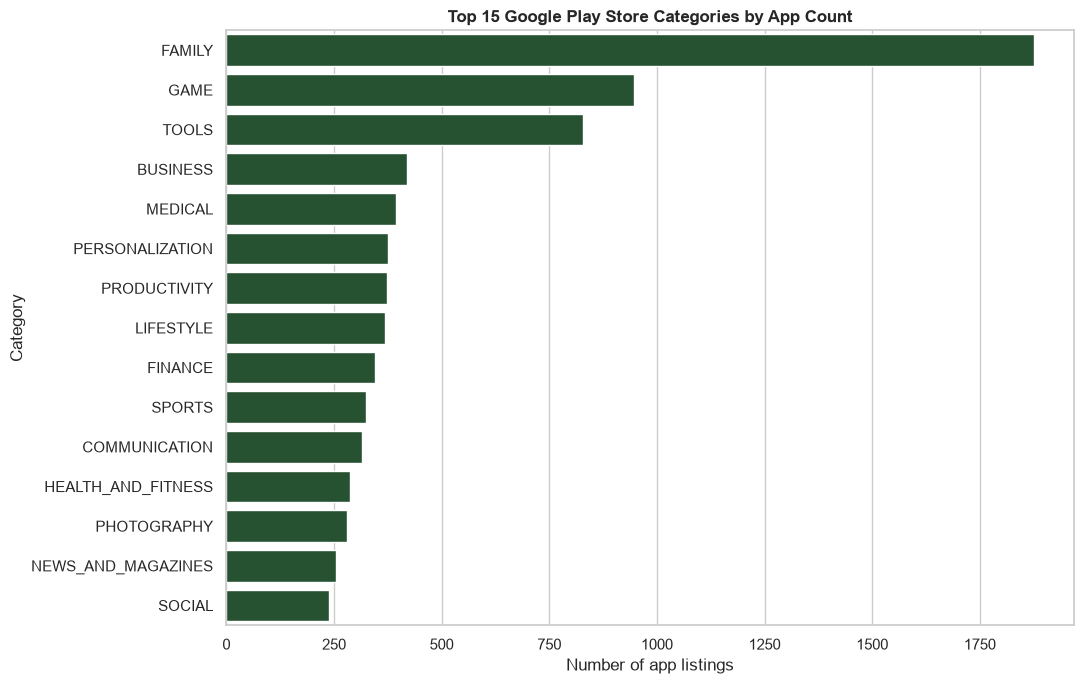

In [9]:
category_counts = df["Category"].value_counts()

plt.figure(figsize=(11, 7))
sns.barplot(
    x=category_counts.head(15).values,
    y=category_counts.head(15).index,
    color="#1F592F"
)
plt.title("Top 15 Google Play Store Categories by App Count", fontweight="bold")
plt.xlabel("Number of app listings")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

FAMILY and GAME are among the most represented categories in the supplied dataset. Use the displayed chart to identify the exact order and counts after cleaning. A category with many listings is not automatically the most successful category.

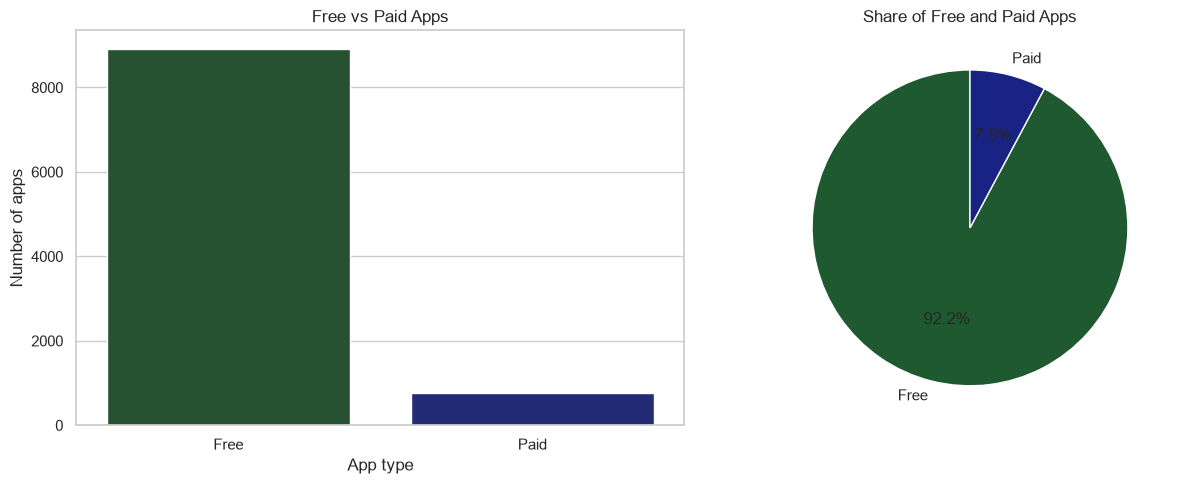

,app_count
app_type,
Free,8905
Paid,754


In [10]:
type_counts = df["app_type"].value_counts().reindex(["Free", "Paid"]).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(x=type_counts.index, y=type_counts.values, ax=axes[0],
            hue=type_counts.index, palette={"Free": "#1F592F", "Paid": "#152083FC"},
            legend=False)
axes[0].set_title("Free vs Paid Apps")
axes[0].set_xlabel("App type")
axes[0].set_ylabel("Number of apps")

axes[1].pie(
    type_counts.values,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#1F592F", "#152083FC"],
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)
axes[1].set_title("Share of Free and Paid Apps")

plt.tight_layout()
plt.show()

display(type_counts.to_frame("app_count"))

A high free-app share describes the marketplace mix; it does not by itself prove that free apps are more profitable or more successful.

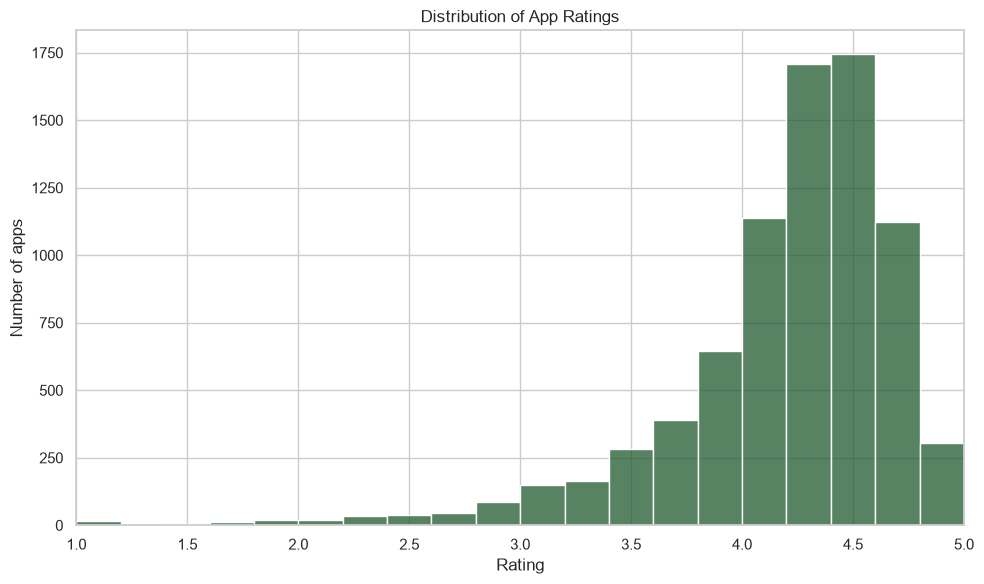

Median rating: 4.3
Mean rating: 4.17


In [11]:
rating_data = df["Rating"].dropna()

plt.figure(figsize=(10, 6))
sns.histplot(rating_data, bins=np.arange(1, 5.11, 0.2), color="#1F592F")
plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of apps")
plt.xlim(1, 5)
plt.tight_layout()
plt.show()

print("Median rating:", round(rating_data.median(), 2))
print("Mean rating:", round(rating_data.mean(), 2))

In this dataset, recorded ratings are generally concentrated in the upper part of the 1–5 scale. Interpret this carefully because unrated apps are excluded and users who submit ratings may not represent all users.

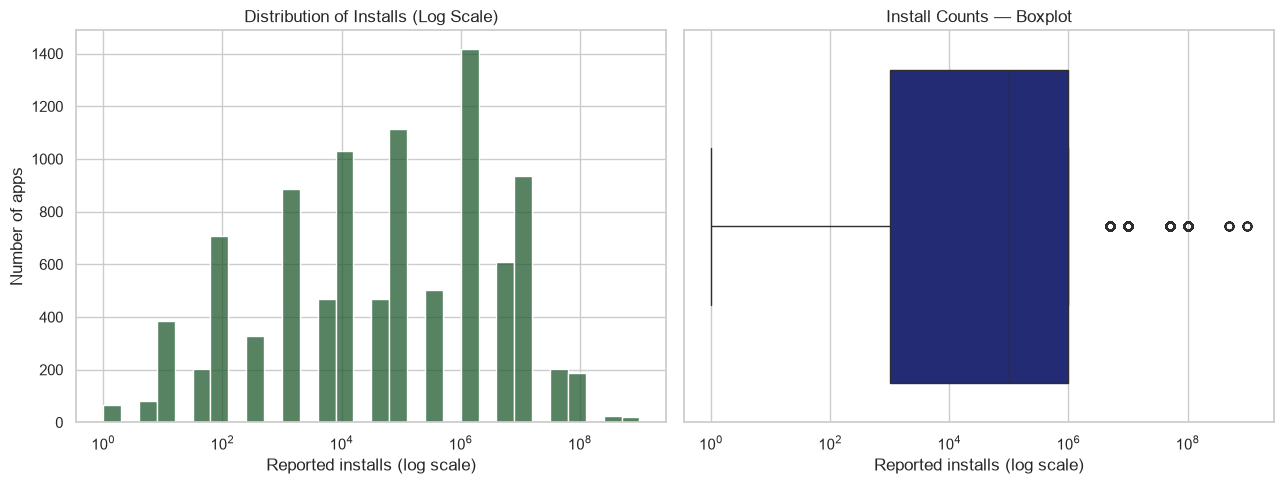

In [12]:
install_data = df.loc[df["installs_num"] > 0, "installs_num"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(install_data, bins=30, log_scale=(True, False),
             color="#1F592F", ax=axes[0])
axes[0].set_title("Distribution of Installs (Log Scale)")
axes[0].set_xlabel("Reported installs (log scale)")
axes[0].set_ylabel("Number of apps")

sns.boxplot(x=install_data, color="#152083FC", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Install Counts — Boxplot")
axes[1].set_xlabel("Reported installs (log scale)")

plt.tight_layout()
plt.show()

Install counts are typically highly right-skewed: many apps have fewer reported installs than a small number of very widely installed apps. Treat these values as approximate lower bounds rather than exact downloads.

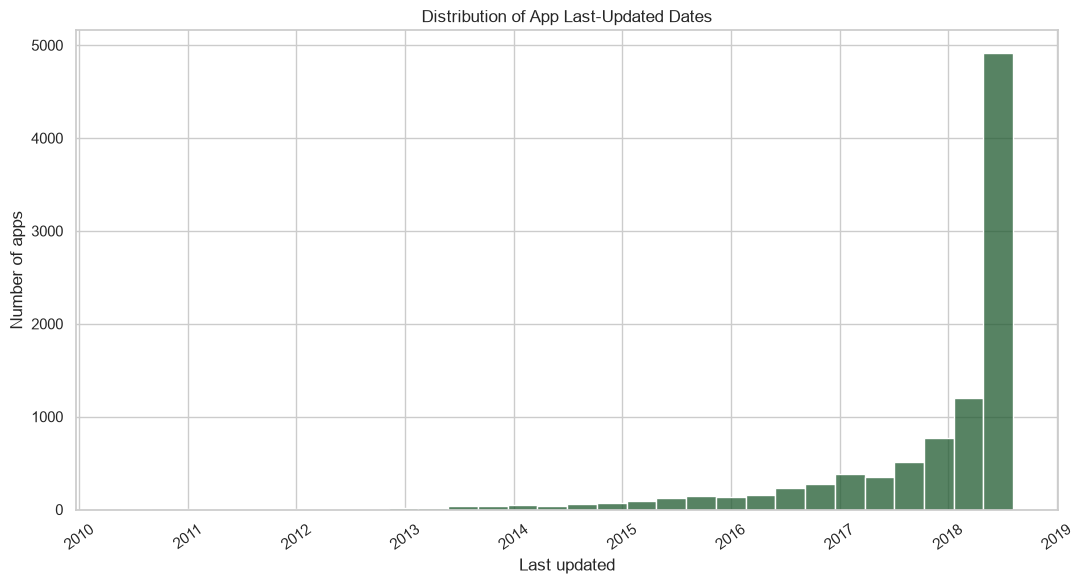

Earliest update: 2010-05-21 00:00:00
Latest update: 2018-08-08 00:00:00


In [13]:
updated = df["last_updated"].dropna()

plt.figure(figsize=(11, 6))
sns.histplot(updated, bins=30, color="#1F592F")
plt.title("Distribution of App Last-Updated Dates")
plt.xlabel("Last updated")
plt.ylabel("Number of apps")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

print("Earliest update:", updated.min())
print("Latest update:", updated.max())

The date distribution reveals when the apps in this snapshot were last updated. Avoid describing this as a current update trend because the dataset is historical and does not contain repeated observations over time.

## BIVARIATE ANALYSIS

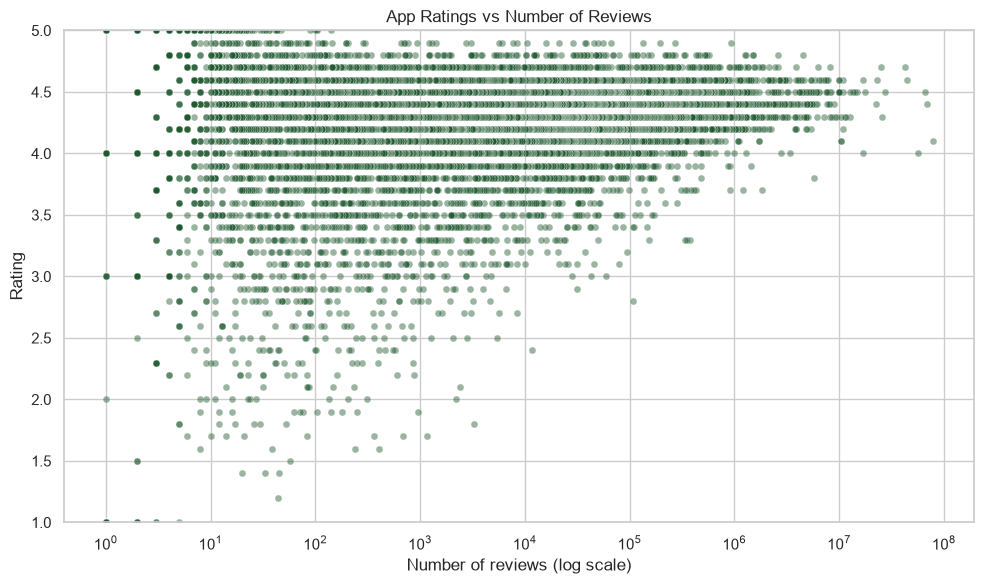

Spearman correlation: 0.12


In [14]:
reviews_rating = df.dropna(subset=["reviews_num", "Rating"]).copy()
reviews_rating = reviews_rating[reviews_rating["reviews_num"] > 0]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=reviews_rating,
    x="reviews_num",
    y="Rating",
    alpha=0.45,
    s=25,
    color="#1F592F"
)
plt.xscale("log")
plt.title("App Ratings vs Number of Reviews")
plt.xlabel("Number of reviews (log scale)")
plt.ylabel("Rating")
plt.ylim(1, 5)
plt.tight_layout()
plt.show()

print("Spearman correlation:",
      round(reviews_rating["reviews_num"].corr(reviews_rating["Rating"], method="spearman"), 3))

The scatterplot shows how ratings vary across review volumes. Use the computed coefficient to describe the strength and direction rather than assuming that popular apps necessarily receive higher ratings. App age, category, and visibility may also influence review volume.

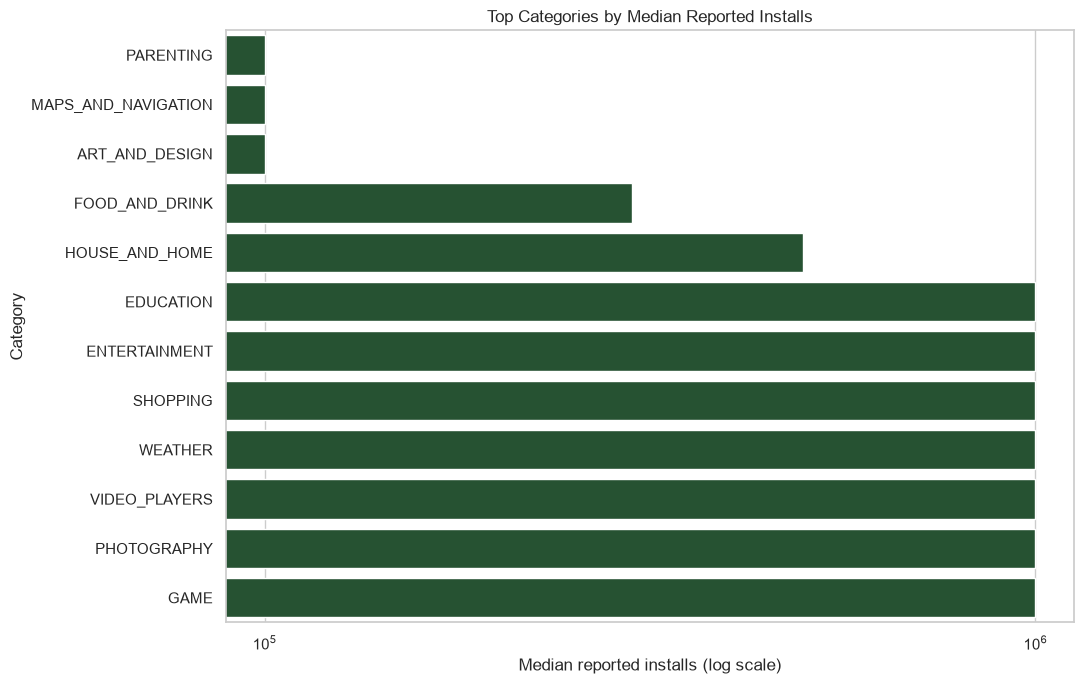

,app_count,median_installs,mean_installs
Category,,,
EDUCATION,107,1000000.0,1.775252e+06
SHOPPING,202,1000000.0,6.932420e+06
ENTERTAINMENT,86,1000000.0,1.144953e+07
GAME,946,1000000.0,1.422614e+07
PHOTOGRAPHY,281,1000000.0,1.657704e+07
VIDEO_PLAYERS,164,1000000.0,2.397502e+07
WEATHER,79,1000000.0,4.570893e+06
HOUSE_AND_HOME,73,500000.0,1.331541e+06
FOOD_AND_DRINK,112,300000.0,1.891060e+06


In [15]:
category_installs = (
    df.dropna(subset=["Category", "installs_num"])
      .groupby("Category")
      .agg(
          app_count=("App", "nunique"),
          median_installs=("installs_num", "median"),
          mean_installs=("installs_num", "mean")
      )
      .sort_values("median_installs", ascending=False)
)

top_category_installs = category_installs.head(12).sort_values("median_installs")

plt.figure(figsize=(11, 7))
sns.barplot(
    data=top_category_installs.reset_index(),
    x="median_installs",
    y="Category",
    color="#1F592F"
)
plt.xscale("log")
plt.title("Top Categories by Median Reported Installs")
plt.xlabel("Median reported installs (log scale)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

display(category_installs.sort_values("median_installs", ascending=False).head(10))

This chart compares typical reported install levels by category, not total market revenue. Use the table to identify the top categories in your cleaned dataset and check their app counts before making strong comparisons.

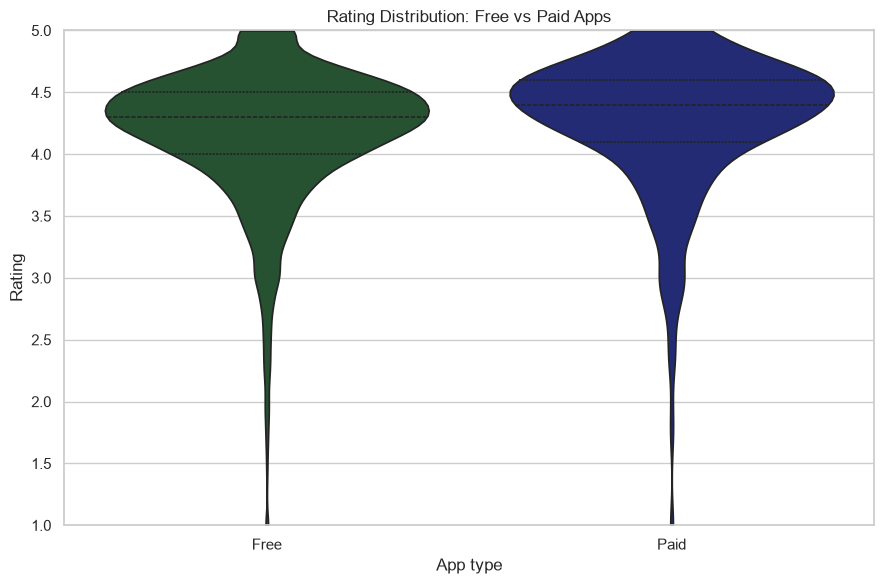

,count,median,mean
app_type,,,
Free,7594,4.3,4.17
Paid,602,4.4,4.26


In [16]:
rating_type = df.dropna(subset=["app_type", "Rating"])
rating_type = rating_type[rating_type["app_type"].isin(["Free", "Paid"])]

plt.figure(figsize=(9, 6))
sns.violinplot(
    data=rating_type,
    x="app_type",
    y="Rating",
    order=["Free", "Paid"],
    inner="quartile",
    cut=0,hue="app_type",legend=False,
    palette={"Free": "#1F592F", "Paid": "#152083FC"},
)
plt.title("Rating Distribution: Free vs Paid Apps")
plt.xlabel("App type")
plt.ylabel("Rating")
plt.ylim(1, 5)
plt.tight_layout()
plt.show()

display(rating_type.groupby("app_type")["Rating"].agg(["count", "median", "mean"]).round(2))

The bar chart compares median app installs across Google Play Store categories, highlighting the categories with the highest typical install counts and differences in app popularity.

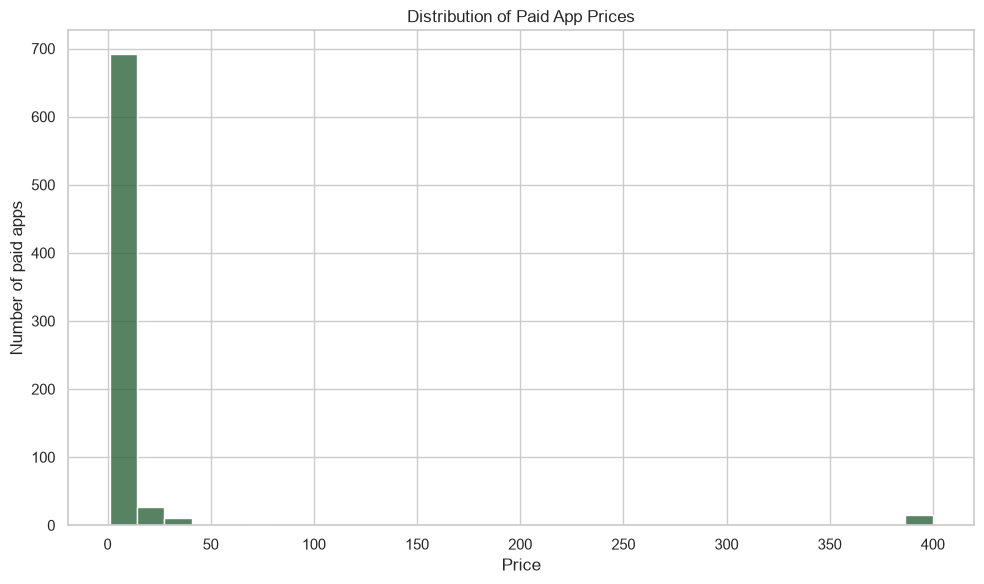

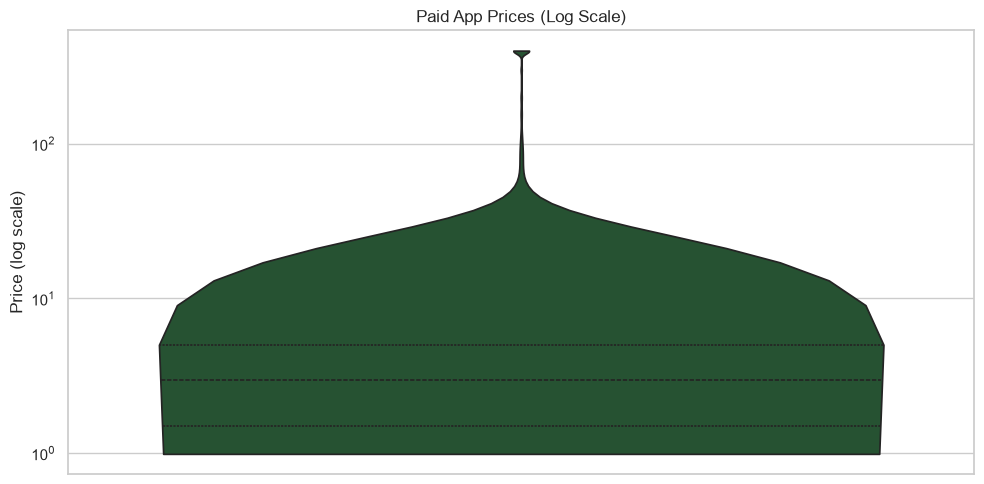

,price_summary
count,754.000000
mean,14.055902
std,58.821000
min,0.990000
25%,1.490000
50%,2.990000
75%,4.990000
max,400.000000


In [17]:
paid = df[(df["app_type"] == "Paid") & (df["price_num"] > 0)].copy()

plt.figure(figsize=(10, 6))
sns.histplot(paid["price_num"], bins=30, color="#1F592F")
plt.title("Distribution of Paid App Prices")
plt.xlabel("Price")
plt.ylabel("Number of paid apps")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.violinplot(data=paid, y="price_num", inner="quartile", cut=0, color="#1F592F")
plt.yscale("log")
plt.title("Paid App Prices (Log Scale)")
plt.ylabel("Price (log scale)")
plt.tight_layout()
plt.show()

display(paid["price_num"].describe().to_frame("price_summary"))

Paid app prices are usually concentrated at lower price points, with a smaller number of expensive apps producing a long right tail. Use the summary statistics and chart to verify the exact distribution in the cleaned data.

## MULTIVARIATE ANALYSIS

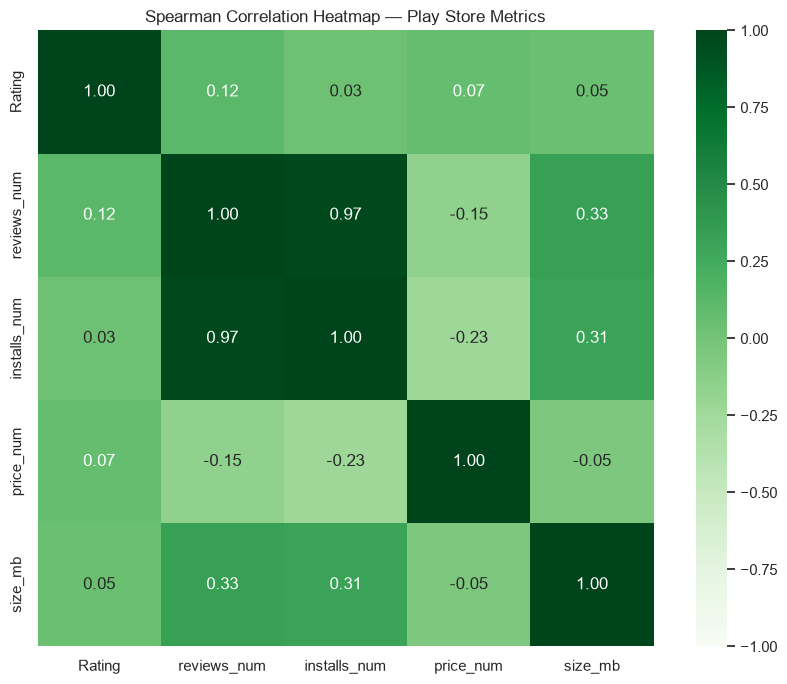

In [18]:
corr_cols = [
    "Rating",
    "reviews_num",
    "installs_num",
    "price_num",
    "size_mb"
]
corr_data = df[corr_cols].copy()

# Spearman is useful as an initial check for skewed variables and monotonic relationships
corr = corr_data.corr(method="spearman", min_periods=30)

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap="Greens",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    square=True
)
plt.title("Spearman Correlation Heatmap — Play Store Metrics")
plt.tight_layout()
plt.show()

Reviews and installs show a very strong positive correlation (0.97).



Price has a weak negative correlation with installs (-0.23).



Rating has very weak correlations with most numerical variables.



Overall, app popularity is more strongly associated with review volume and installs than with ratings or price.